In [7]:
import scipy as sp
from scipy.stats import qmc
from numpy.random import Generator, PCG64
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
folder = '../../../Data/'
df_interactions = pd.read_excel(folder+'Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions (GTPR25)')
df_interactions.head()

no_samples = 500
no_edges = len(df_interactions)
seed = 45643564852856852352111
sampler = qmc.LatinHypercube(d = no_edges,rng=Generator(PCG64(seed))) # 17 edges
sample = sampler.random(n=no_samples) # still in a [0,1]^17 hypercube 500 samples!
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM'] # see README.txt
TE_to_ind = {te:i for i,te in enumerate(TEs)}

a = df_interactions['min'].to_numpy()
b = df_interactions['max'].to_numpy()
A = []
for r in range(no_samples):
    weights = a+sample[r,:]*(b-a)
    mat = np.zeros([len(TEs)]*2)
    for index, row in df_interactions.iterrows():
        i = TE_to_ind[row['Source']]
        j = TE_to_ind[row['Target']]
        mat[i,j] = weights[index]
    A.append(mat)
    np.savetxt("../../../Data/Interaction matrices/GTPR2025/A_%s.csv"%r,A[r])

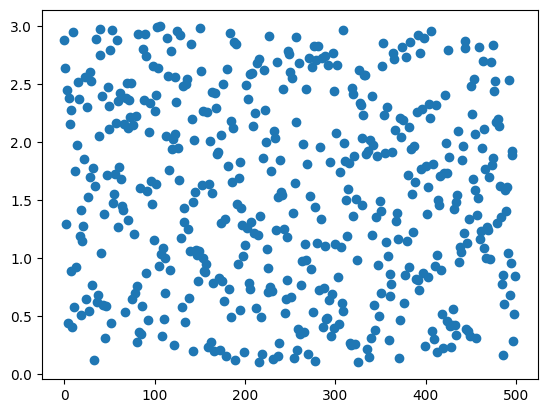

In [16]:
plt.scatter(np.arange(500),[A[r][-2,1] for r in range(500)])

In [14]:
### Pre-generated interaction matrices from Wunderling 2024
len_sample=500
A_W24 = np.array([np.loadtxt('../../../Data/Interaction matrices/Wunderling 2024/A_%s.csv'%r) for r in range(len_sample)])
A_GTP = np.array([np.loadtxt('../../../Data/Interaction matrices/GTPR2025/A_%s.csv'%r) for r in range(len_sample)])

In [4]:
np.array(A_W24).shape

(500, 9, 9)

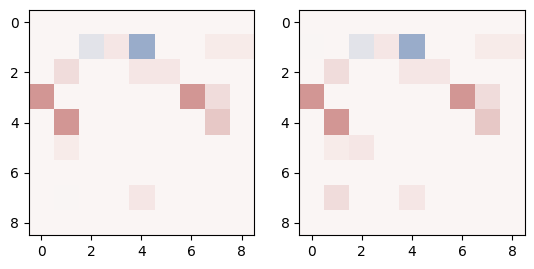

In [17]:
fig,axs=plt.subplots(ncols=2)
axs[0].imshow(np.mean(np.array(A_W24),axis=0),cmap='vlag',vmin=-10,vmax=10)
axs[1].imshow(np.mean(np.array(A_GTP),axis=0),cmap='vlag',vmin=-10,vmax=10)

NameError: name 'df_TEs' is not defined

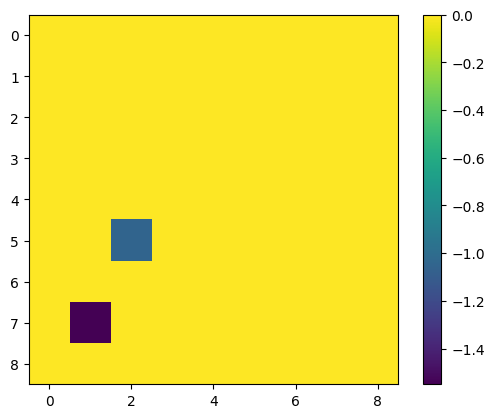

In [19]:
im=plt.imshow(np.mean(A_W24-A_GTP,axis=0))
plt.colorbar(im)

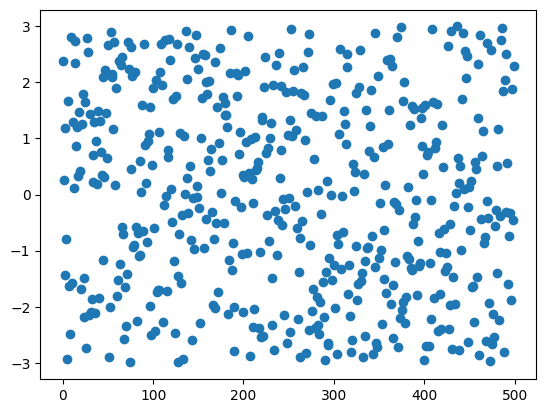

In [22]:
plt.scatter(np.arange(500),A_W24[:,7,1])

In [28]:
folder = '../../../Data/'
df_interactions = pd.read_excel(folder+'Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions')
df_interactions.head()

no_samples = 500
no_edges = len(df_interactions)
seed = 45643564852856852352111
sampler = qmc.LatinHypercube(d = no_edges,rng=Generator(PCG64(seed))) # 17 edges
sample = sampler.random(n=no_samples) # still in a [0,1]^17 hypercube 500 samples!
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM'] # see README.txt
TE_to_ind = {te:i for i,te in enumerate(TEs)}

a = df_interactions['min'].to_numpy()
b = df_interactions['max'].to_numpy()
A = []
for r in range(no_samples):
    weights = a+sample[r,:]*(b-a)
    mat = np.zeros([len(TEs)]*2)
    for index, row in df_interactions.iterrows():
        i = TE_to_ind[row['Source']]
        j = TE_to_ind[row['Target']]
        mat[i,j] = weights[index]
    A.append(mat)

In [29]:
A[0]

array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ],
       [-3.8184616 ,  0.        , -0.47498012,  1.05694677, -3.79565399,
         0.        ,  0.        ,  0.7870778 ,  0.52943007],
       [ 0.        ,  1.93165459,  0.        ,  0.        ,  1.02192573,
         0.52597723,  0.        ,  0.        ,  0.        ],
       [ 9.36716764,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  5.35374901,  0.45741812,  0.        ],
       [ 0.        ,  4.22085785,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  2.09699642,  0.        ],
       [ 0.        ,  1.03498855,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  2.38421841,  0.        ,  0.        ,  0